# М4. Бильярд на реальном столе

Качение с проскальзыванием и без него.

Сопротивлением воздуха и качением пренебрегли. Поэтому на горизонтальном столе после окончания скольжения шар не останавливается.

In [1]:
from dataclasses import dataclass, replace
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.35,
    "axes.formatter.use_mathtext": True,
})

def plot_lines(ax, t, series, title, ylabel):
    for values, label in series:
        ax.plot(t, values, label=label)
    ax.set(title=title, xlabel="Время, с", ylabel=ylabel)
    ax.legend(fontsize=9)

## 1. Модель и параметры

Ось $x$ направлена вниз по склону. $v$ - скорость центра, $\omega$ - угловая скорость, $R$ - радиус. Вращение положительно в направлении качения при $v>0$.

### Параметры

Бильярдный шар: масса **170 г**, диаметр **57,15 мм** - было взято вот [отсюда](https://wpapool.com/wp-content/uploads/2024/01/RECOMMENDED-EQUIPMENT-SPECIFICATIONS.pdf). Начальная скорость - **2 м/с**.

Другой пример - деревянный цилиндр массой **250 г**, радиусом **3 см**. Уклоны 5° и 25° соответствуют наклонной доске и учебному жёлобу. Коэффициенты трения выбраны для моделирования, а не взяты из измерений.


В `Ball` хранятся координата, скорость, угол, угловая скорость и тепло. Момент инерции $I=\beta mR^2$, радиус - половина диаметра. Для чистого качения $\omega_0=v_0/R$. Углы переводятся в радианы: $\alpha_{\rm рад}=\alpha_{\rm град}\pi/180$.


In [ ]:
G = 9.81                         # м/с²
RTOL, ATOL = 1e-10, 1e-12         # точность интегрирования
MAX_STEP = 0.01                   # максимальный шаг, с
SAMPLES = 601                     # число точек для графика
CONTACT_TOL = 1e-10               # порог скорости скольжения, м/с
TIME_TOL = 1e-12                  # порог округления времени, с

@dataclass
class Ball:
    mass: float
    radius: float
    translational_velocity: float
    angular_velocity: float
    position: float = 0.0
    angle: float = 0.0
    beta: float = 2/5             # 2/5 - шар, 1/2 - цилиндр
    heat: float = 0.0

    @property
    def rotational_inertia(self):
        return self.beta*self.mass*self.radius**2

@dataclass(frozen=True)
class Environment:
    incline_angle: float          # радианы
    friction_coefficient: float
    plane_length: float
    static_friction_coefficient: float = 0.25

@dataclass
class Experiment:
    name: str
    ball: Ball
    environment: Environment
    duration: float = 0.8

BALL = Ball(0.170, 0.028575, 2.0, 0.0)
SURFACE = Environment(0.0, 0.20, 3.0)
INCLINE = replace(SURFACE, incline_angle=np.radians(5))
TABLE = Experiment("Шар: удар без закрутки", BALL, SURFACE)
EXPERIMENTS = [
    TABLE,
    replace(TABLE, name="Шар: обратная закрутка", ball=replace(BALL, angular_velocity=-60)),
    replace(TABLE, name="Шар: накат", ball=replace(BALL, angular_velocity=100)),
    replace(TABLE, name="Шар: чистое качение", ball=replace(BALL, angular_velocity=2/BALL.radius)),
    Experiment("Шар: склон 5°, из покоя", replace(BALL, translational_velocity=0), INCLINE, 1.5),
    Experiment("Шар: склон 5°, со скольжением", BALL, INCLINE, 1.2),
    Experiment("Шар: вверх по склону 5°", replace(BALL, translational_velocity=-0.5,
               angular_velocity=-0.5/BALL.radius), INCLINE, 1.5),
    Experiment("Цилиндр: склон 25°, из покоя", Ball(0.25, 0.03, 0, 0, beta=0.5),
               Environment(np.radians(25), 0.10, 3.0, 0.12)),
]
MAIN_INDEX = 5
MAIN = EXPERIMENTS[MAIN_INDEX]
ANGLE_SCAN = np.linspace(0, 35, 141)

## 2. Расчёт движения

`Ball` - состояние тела, `Environment` - поверхность, `Calculator` - переключение режимов.

Для функций движения:
$$u=v-R\omega,\quad N=mg\cos\alpha,\quad I=\beta mR^2.$$
При скольжении:
$$F=-\mu_kN\operatorname{sgn}u,\quad a=g\sin\alpha+F/m,\quad \varepsilon=-FR/I.$$
При чистом качении:
$$a=\frac{g\sin\alpha}{1+\beta},\quad \varepsilon=a/R,\quad\omega=v/R.$$
`move_with_accelerations` решает:
$$\dot x=v,\quad\dot v=a,\quad\dot\varphi=\omega,\quad\dot\omega=\varepsilon,\quad\dot Q=-Fu.$$
При чистом качении $\dot Q=0$. При $u=0$ и недостаточном трении начинающееся скольжение направлено по знаку $\sin\alpha$.

Функции `is_slippage_finished` и `is_movement_without_slippage_possible` используют условия
$$|u|\leq\texttt{CONTACT\_TOL},\qquad\frac{\beta}{1+\beta}|\tan\alpha|\leq\mu_s.$$
Здесь $\mu_k$ - трение скольжения, $\mu_s$ - трение покоя.

In [3]:
def is_slippage_finished(ball):
    return abs(ball.translational_velocity-ball.radius*ball.angular_velocity) <= CONTACT_TOL

def is_movement_without_slippage_possible(ball, env):
    return ball.beta/(1+ball.beta)*abs(np.tan(env.incline_angle)) <= env.static_friction_coefficient

def friction_force(ball, env):
    slip = ball.translational_velocity-ball.radius*ball.angular_velocity
    sign = np.sign(np.sin(env.incline_angle)) if is_slippage_finished(ball) else np.sign(slip)
    return -env.friction_coefficient*ball.mass*G*np.cos(env.incline_angle)*sign

def move_with_accelerations(ball, time_delta, a, eps, friction=0.0):
    def rhs(t, y):
        return [y[1], a, y[3], eps, -friction*(y[1]-ball.radius*y[3])]
    initial = [ball.position, ball.translational_velocity, ball.angle, ball.angular_velocity, ball.heat]
    sol = solve_ivp(rhs, (0, time_delta), initial, max_step=MAX_STEP, rtol=RTOL, atol=ATOL)
    x, v, angle, omega, heat = sol.y[:, -1]
    return replace(ball, position=x, translational_velocity=v, angle=angle, angular_velocity=omega, heat=heat)

def move_with_slippage(ball, env, time_delta):
    F = friction_force(ball, env)
    return move_with_accelerations(ball, time_delta, G*np.sin(env.incline_angle)+F/ball.mass,
                                   -F*ball.radius/ball.rotational_inertia, F)

def move_without_slippage(ball, env, time_delta):
    a = G*np.sin(env.incline_angle)/(1+ball.beta)
    ball = replace(ball, angular_velocity=ball.translational_velocity/ball.radius)
    return move_with_accelerations(ball, time_delta, a, a/ball.radius)

### Переключение режимов

За участок с постоянными ускорениями:
$$u(t)=u_0+bt,\qquad b=a-R\varepsilon
=g\sin\alpha+\frac Fm\left(1+\frac1\beta\right).$$
Если $u_0b<0$, время до исчезновения скольжения $t_*=-u_0/b$; иначе $t_*=\infty$. `Calculator` берёт
$$\Delta t=\min(t_{\rm конец}-t_{\rm текущ},\ t_*).$$
В момент $u=0$ устанавливаем $\omega=v/R$ и заново выбираем режим.

Для длительности $T$ и шага выдачи $\delta t$ функция `simulate` задаёт
$$n=\lceil T/\delta t\rceil,\qquad t_k=kT/n,\quad k=0,\ldots,n.$$
Расчёт заканчивается по времени или при $x\geq\ell$. `TIME_TOL` учитывает округление чисел при выборе шага.

In [4]:
class Calculator:
    def __init__(self, ball, env):
        self.current_ball, self.env = replace(ball), env
        self.current_time = 0.0
        self.transitions = []

    def _compute_next(self, time_delta):
        ball, env = self.current_ball, self.env
        if is_slippage_finished(ball) and is_movement_without_slippage_possible(ball, env):
            return move_without_slippage(ball, env, time_delta)
        return move_with_slippage(ball, env, time_delta)

    def __call__(self, time_delta):
        end = self.current_time+time_delta
        while end-self.current_time > TIME_TOL:
            ball, env = self.current_ball, self.env
            slip = ball.translational_velocity-ball.radius*ball.angular_velocity
            force = friction_force(ball, env)
            slip_acceleration = G*np.sin(env.incline_angle)+force/ball.mass*(1+1/ball.beta)
            switch = -slip/slip_acceleration if not is_slippage_finished(ball) and slip*slip_acceleration < 0 else np.inf
            step = min(end-self.current_time, switch)
            self.current_ball = self._compute_next(step)
            self.current_time += step
            if switch <= step:
                self.current_ball = replace(self.current_ball,
                    angular_velocity=self.current_ball.translational_velocity/ball.radius)
                self.transitions.append(self.current_time)
        return self.current_ball

def simulate(calculator, sampling_delta, duration):
    yield calculator.current_ball
    steps = int(np.ceil(duration/sampling_delta-TIME_TOL))
    for target in np.linspace(0, duration, steps+1)[1:]:
        if calculator.current_ball.position >= calculator.env.plane_length:
            break
        yield calculator(target-calculator.current_time)

def simulate_experiment(p):
    calculator = Calculator(p.ball, p.environment)
    times, states = [], []
    for ball in simulate(calculator, p.duration/(SAMPLES-1), p.duration):
        times.append(calculator.current_time)
        states.append([ball.position, ball.translational_velocity, ball.angle, ball.angular_velocity, ball.heat])
    return dict(p=p, t=np.array(times), y=np.array(states).T, transitions=calculator.transitions)

RESULTS = [simulate_experiment(p) for p in EXPERIMENTS]
result = RESULTS[MAIN_INDEX]
print("Время перехода:", [round(float(t), 6) for t in result["transitions"]], "с")

Время перехода: [0.33412] с


## 3. Результаты и сравнение с теорией

Совпадение $v$ и $R\omega$ означает чистое качение.

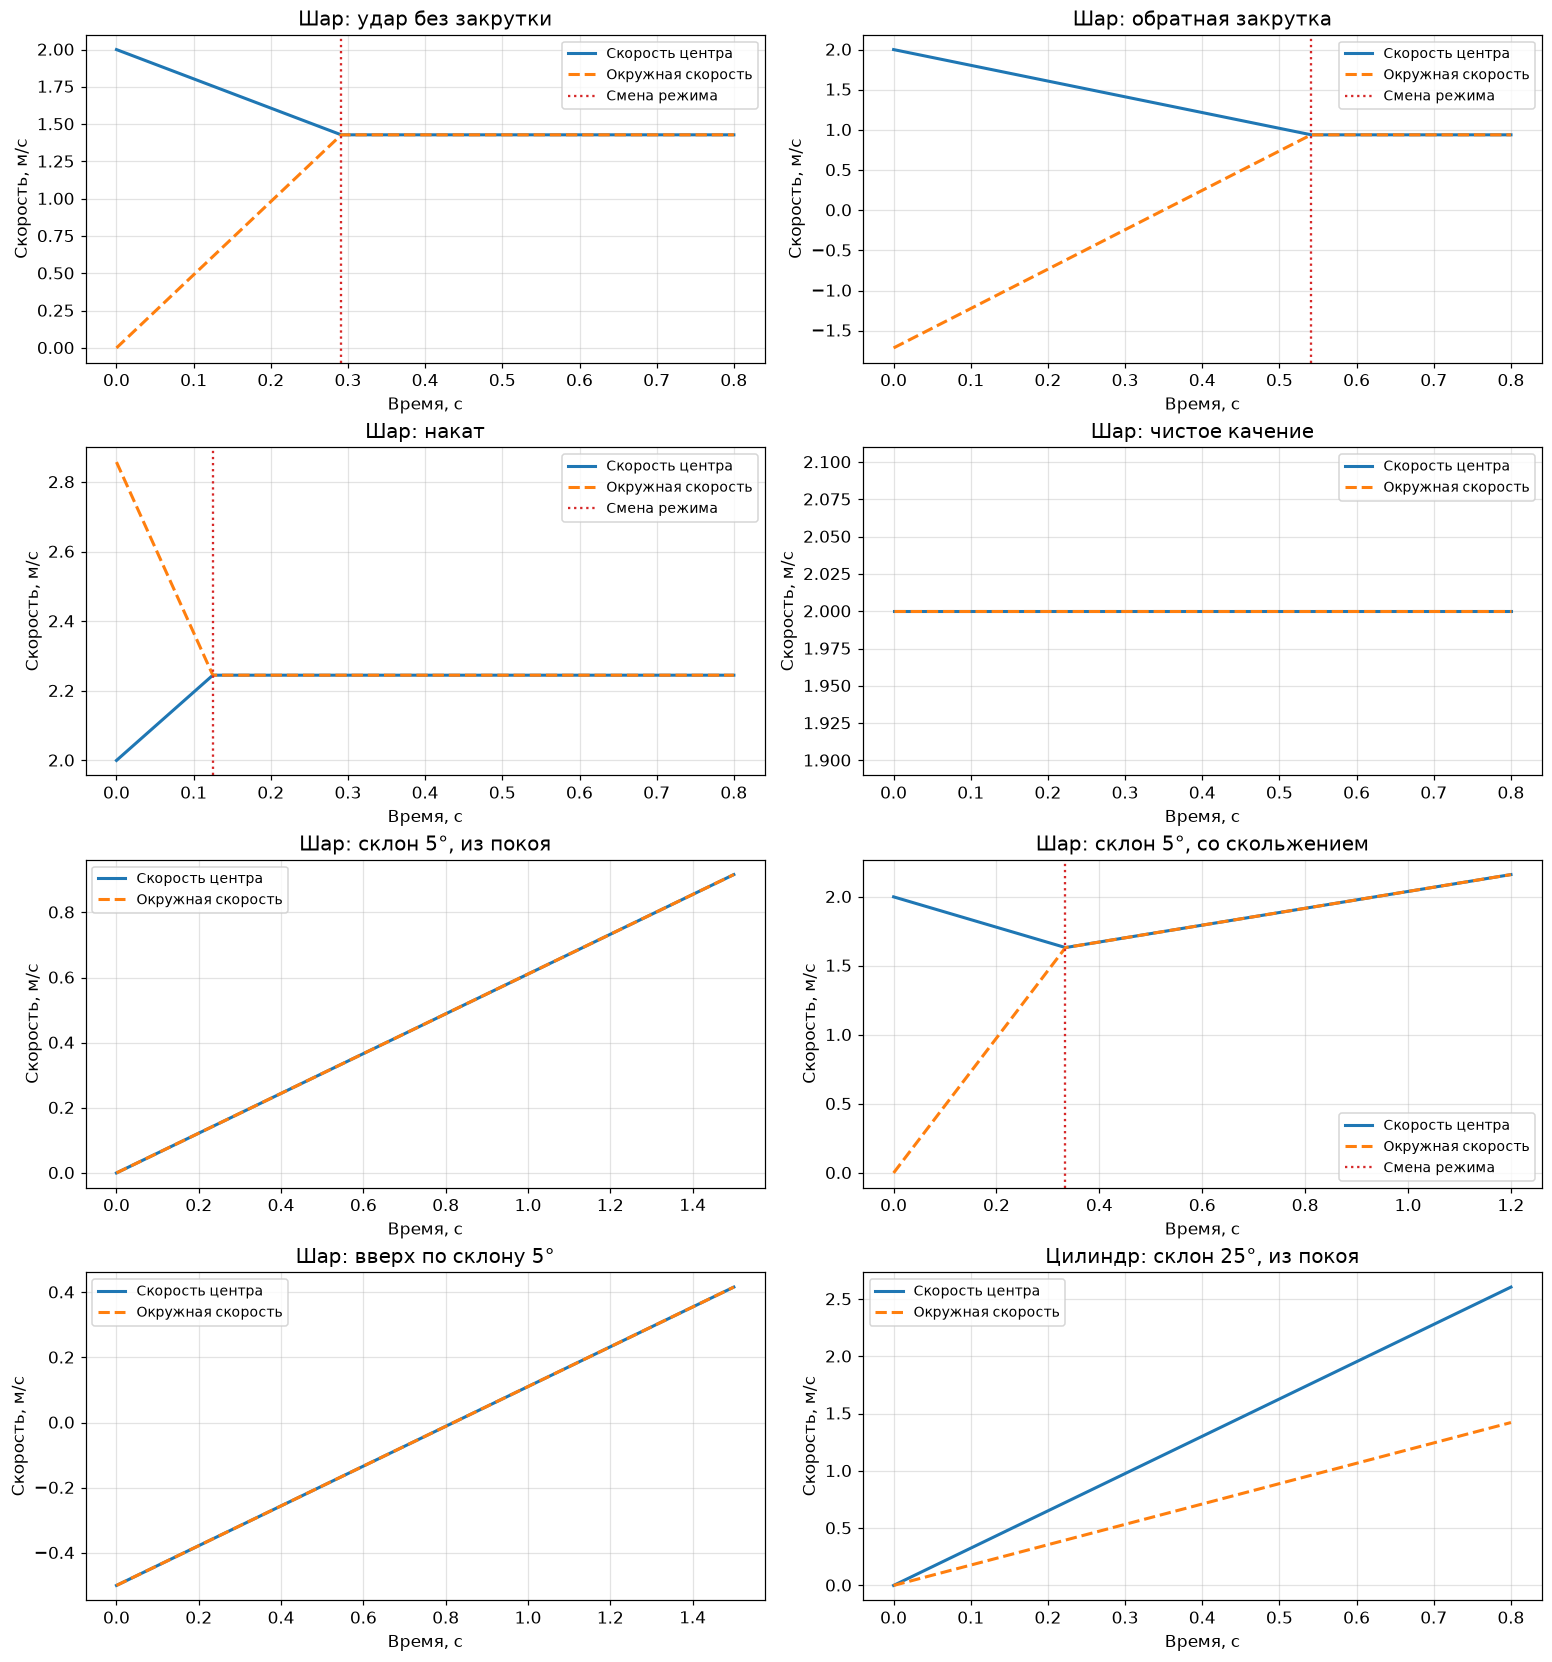

In [5]:
fig, axes = plt.subplots(4, 2, figsize=(14, 15), layout="constrained")
for ax, r in zip(axes.flat, RESULTS):
    p, t, y = r["p"], r["t"], r["y"]
    ax.plot(t, y[1], label="Скорость центра", linewidth=2)
    ax.plot(t, p.ball.radius * y[3], "--", label="Окружная скорость", linewidth=2)
    for j, switch in enumerate(r["transitions"]):
        ax.axvline(switch, color="tab:red", linestyle=":",
                   label="Смена режима" if j == 0 else None)
    ax.set(title=p.name, xlabel="Время, с", ylabel="Скорость, м/с")
    ax.legend(fontsize=9)
plt.show()

### Координата и проскальзывание

Строим $x(t)$ и $u(t)=v(t)-R\omega(t)$. Вертикальная линия отмечает момент $u=0$.

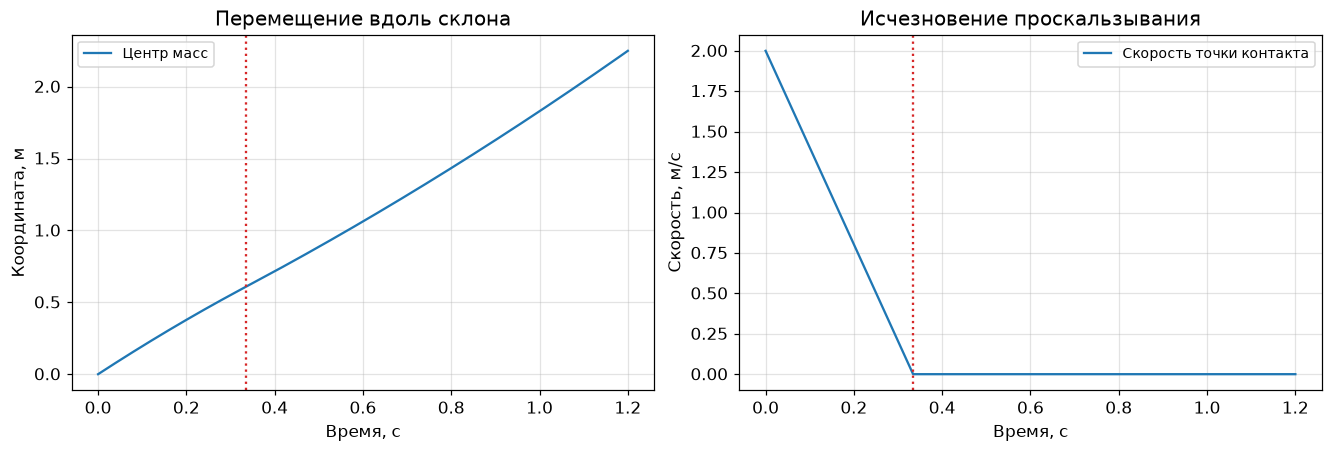

In [6]:
p, t, y = result["p"], result["t"], result["y"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
plot_lines(axes[0], t, [(y[0], "Центр масс")], "Перемещение вдоль склона", "Координата, м")
plot_lines(axes[1], t, [(y[1]-p.ball.radius*y[3], "Скорость точки контакта")], "Исчезновение проскальзывания", "Скорость, м/с")
for ax in axes:
    for switch in result["transitions"]:
        ax.axvline(switch, color="tab:red", linestyle=":")
plt.show()

### Сравнение с теорией

В `theory` используются те же ускорения $a,\varepsilon$, что и в модели движения. На одном участке:
$$v=v_0+at,\qquad x=x_0+v_0t+\frac{at^2}{2},$$
$$\omega=\omega_0+\varepsilon t,\qquad
\varphi=\varphi_0+\omega_0t+\frac{\varepsilon t^2}{2}.$$
Для двух участков берём $t_1=\min(t,t_*)$, $t_2=\max(t-t_*,0)$. Сначала применяем формулы на времени $t_1$, затем - на $t_2$, начиная с состояния конца первого участка. $t_*$ находится из $u_0+(a-R\varepsilon)t_*=0$; если скольжение не прекращается, $t_*=\infty$.

Для шара на столе без закрутки ($v_0>0$, $\mu_k>0$):
$$t_*=\frac{2v_0}{7\mu_k g},\qquad v_*=\frac57v_0.$$


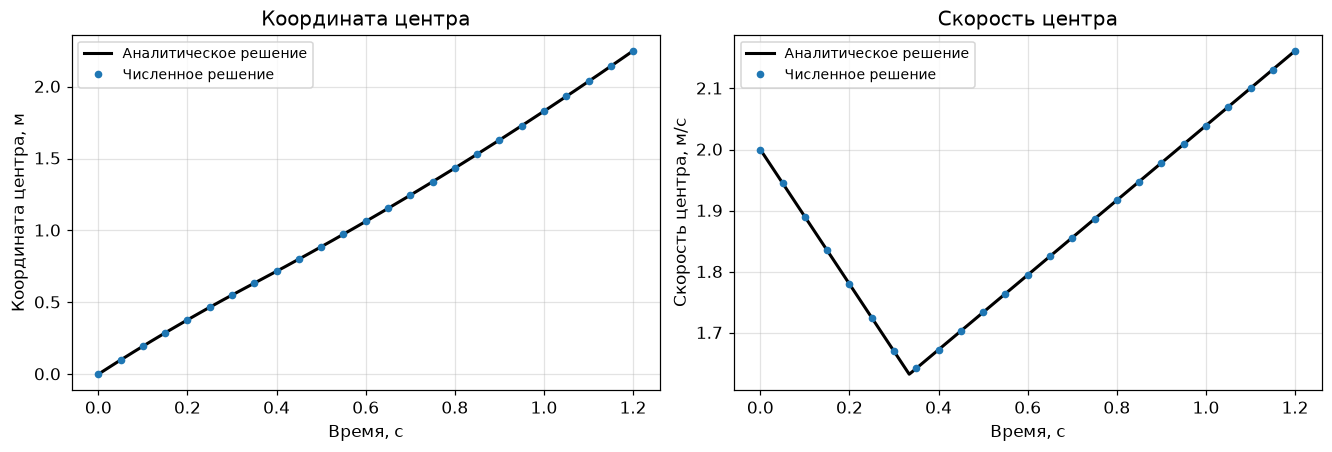

Время перехода по формуле: 0.334120 с
Время перехода численно:   0.334120 с
Для удара без закрутки на столе v* = 1.428571 м/с


In [7]:
def theory(p, t):
    ball, env = p.ball, p.environment
    m, R, beta = ball.mass, ball.radius, ball.beta
    v0, w0 = ball.translational_velocity, ball.angular_velocity
    drive, N = G*np.sin(env.incline_angle), m*G*np.cos(env.incline_angle)
    u0 = v0-R*w0
    contact = abs(u0) <= CONTACT_TOL
    if contact:
        w0 = v0/R
    can_roll = beta/(1+beta)*abs(np.tan(env.incline_angle)) <= env.static_friction_coefficient
    def accelerations(contact, sign):
        F = -m*beta*drive/(1+beta) if contact and can_roll else -env.friction_coefficient*N*sign
        return drive+F/m, -F*R/ball.rotational_inertia
    a, eps = accelerations(contact, np.sign(drive) if contact else np.sign(u0))
    b = a-R*eps
    switch = -u0/b if not contact and u0*b < 0 else np.inf
    t1, t2 = np.minimum(t, switch), np.maximum(t-switch, 0)
    a2, eps2 = accelerations(True, np.sign(drive))
    x = ball.position+v0*t1+a*t1**2/2+(v0+a*t1)*t2+a2*t2**2/2
    v = v0+a*t1+a2*t2
    phi = ball.angle+w0*t1+eps*t1**2/2+(w0+eps*t1)*t2+eps2*t2**2/2
    return np.array([x, v, phi, w0+eps*t1+eps2*t2]), switch

exact, switch_theory = theory(MAIN, result["t"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, row, title, unit in zip(axes, [0, 1],
                              ["Координата центра", "Скорость центра"], ["м", "м/с"]):
    ax.plot(result["t"], exact[row], color="black", linewidth=2, label="Аналитическое решение")
    ax.plot(result["t"][::25], result["y"][row, ::25], "o", markersize=4,
            label="Численное решение")
    ax.set(title=title, xlabel="Время, с", ylabel=f"{title}, {unit}")
    ax.legend(fontsize=9)
plt.show()

print(f"Время перехода по формуле: {switch_theory:.6f} с")
print(f"Время перехода численно:   {result['transitions'][0]:.6f} с")
print(f"Для удара без закрутки на столе v* = {5 * TABLE.ball.translational_velocity / 7:.6f} м/с")

### Энергия

$$K=\frac{mv^2}{2}+\frac{I\omega^2}{2},\qquad U=-mg(x-x_0)\sin\alpha.$$
$$E=K+U,\qquad E+Q=\mathrm{const}.$$

При скольжении энергия переходит в тепло $Q$. При чистом качении $E$ сохраняется.

В `energy_and_momentum` составляющие считаются отдельно:
$$K_{\rm пост}=mv^2/2,\qquad K_{\rm вращ}=I\omega^2/2.$$
Эта же функция вычисляет момент импульса относительно неподвижной точки плоскости:
$$L=I\omega+mRv,\qquad L_{\rm теория}=L(0)+mgR\sin\alpha\,t.$$

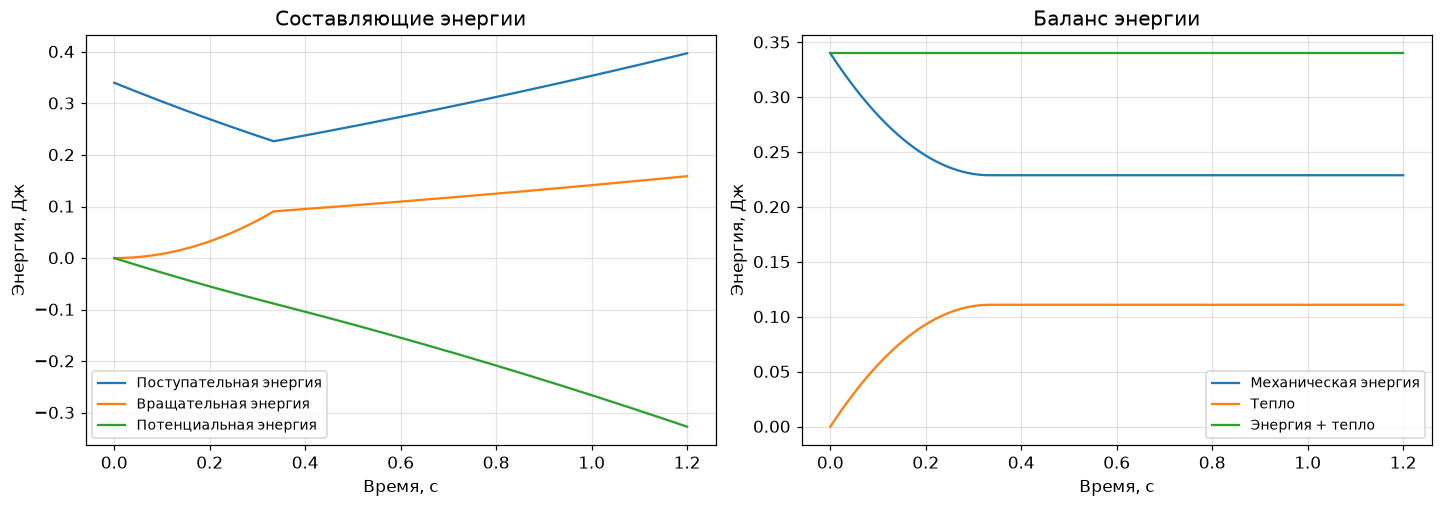

In [8]:
def energy_and_momentum(r):
    p, t, y = r["p"], r["t"], r["y"]
    drive = G*np.sin(p.environment.incline_angle)
    inertia = p.ball.rotational_inertia
    kinetic_translation = p.ball.mass * y[1]**2 / 2
    kinetic_rotation = inertia * y[3]**2 / 2
    potential = -p.ball.mass * drive * (y[0] - p.ball.position)
    energy = kinetic_translation + kinetic_rotation + potential
    angular_momentum = inertia * y[3] + p.ball.mass * p.ball.radius * y[1]
    momentum_expected = angular_momentum[0] + p.ball.mass * p.ball.radius * drive * t
    return kinetic_translation, kinetic_rotation, potential, energy, angular_momentum, momentum_expected

kt, kr, potential, energy, _, _ = energy_and_momentum(result)
t, heat = result["t"], result["y"][4]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
plot_lines(axes[0], t, [(kt, "Поступательная энергия"), (kr, "Вращательная энергия"),
                       (potential, "Потенциальная энергия")], "Составляющие энергии", "Энергия, Дж")
plot_lines(axes[1], t, [(energy, "Механическая энергия"), (heat, "Тепло"),
                       (energy+heat, "Энергия + тепло")], "Баланс энергии", "Энергия, Дж")
plt.show()

### Момент импульса

Относительно неподвижной точки плоскости под начальным положением центра:
$$L=I\omega+mRv,\qquad L(t)=L(0)+mgR\sin\alpha\,t.$$
На горизонтальном столе $L$ сохраняется, на наклонном - меняется по этой формуле.

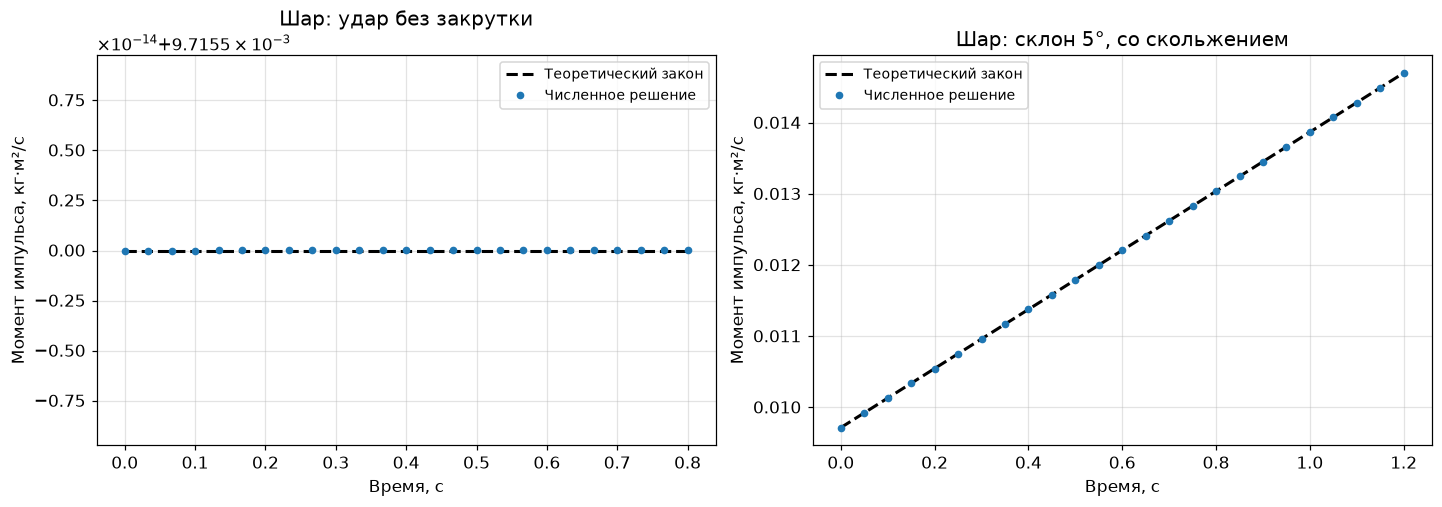

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
for ax, r in zip(axes, [RESULTS[0], result]):
    *_, momentum, expected = energy_and_momentum(r)
    ax.plot(r["t"], expected, "k--", linewidth=2, label="Теоретический закон")
    ax.plot(r["t"][::25], momentum[::25], "o", markersize=4, label="Численное решение")
    ax.set(title=r["p"].name, xlabel="Время, с", ylabel="Момент импульса, кг·м²/с")
    ax.legend(fontsize=9)
plt.show()

### Условие чистого качения

Для старта из покоя требуется:
$$\mu_s\geq\frac{\beta}{1+\beta}|\tan\alpha|.$$
Цилиндру нужно большее трение, чем шару. При начальном скольжении дополнительно проверяем, стремится ли $u$ к нулю.

На графике строим $\mu_{s,\min}=\dfrac{\beta}{1+\beta}|\tan\alpha|$. Критический угол:
$$\alpha_{\rm кр}=\arctan\left(\mu_s\frac{1+\beta}{\beta}\right).$$
Для вывода в градусах умножаем результат на $180/\pi$.

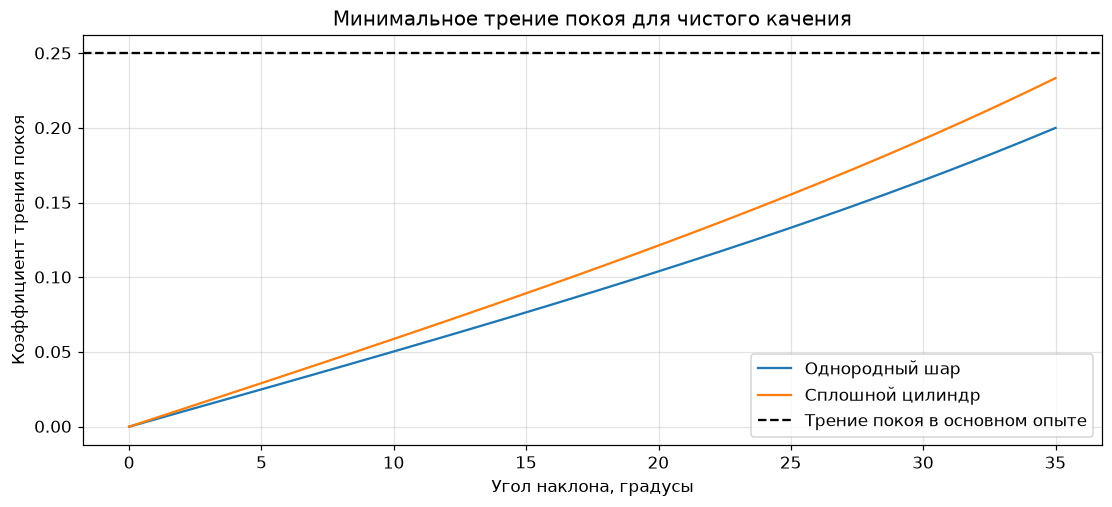

Шар: склон 5°, со скольжением: критический угол 41.19°, заданный угол 5.0°
Цилиндр: склон 25°, из покоя: критический угол 19.80°, заданный угол 25.0°


In [10]:
fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
for beta, name in [(TABLE.ball.beta, "Однородный шар"), (EXPERIMENTS[-1].ball.beta, "Сплошной цилиндр")]:
    required = beta / (1 + beta) * np.tan(np.radians(ANGLE_SCAN))
    ax.plot(ANGLE_SCAN, required, label=name)
ax.axhline(TABLE.environment.static_friction_coefficient, linestyle="--", color="black", label="Трение покоя в основном опыте")
ax.set(title="Минимальное трение покоя для чистого качения",
       xlabel="Угол наклона, градусы", ylabel="Коэффициент трения покоя")
ax.legend()
plt.show()

for p in [MAIN, EXPERIMENTS[-1]]:
    critical = np.degrees(np.arctan(p.environment.static_friction_coefficient * (1 + p.ball.beta) / p.ball.beta))
    print(f"{p.name}: критический угол {critical:.2f}°, заданный угол {np.degrees(p.environment.incline_angle):.1f}°")

### Баланс энергии

Сравниваем сумму механической энергии и тепла в начале и конце каждого опыта.

Для каждого опыта выводим $E_{\rm сум}(0)$ и $E_{\rm сум}(T)$, где $E_{\rm сум}=E+Q$.

In [11]:
print(f"{'Опыт':48} {'Энергия + тепло: начало / конец, Дж'}")
for r in RESULTS:
    energy = energy_and_momentum(r)[3]
    total = energy+r["y"][4]
    print(f"{r['p'].name:48} {total[0]:.6f} / {total[-1]:.6f}")

Опыт                                             Энергия + тепло: начало / конец, Дж
Шар: удар без закрутки                           0.340000 / 0.340000
Шар: обратная закрутка                           0.439943 / 0.439943
Шар: накат                                       0.617620 / 0.617620
Шар: чистое качение                              0.476000 / 0.476000
Шар: склон 5°, из покоя                          0.000000 / -0.000000
Шар: склон 5°, со скольжением                    0.340000 / 0.340000
Шар: вверх по склону 5°                          0.029750 / 0.029750
Цилиндр: склон 25°, из покоя                     0.000000 / 0.000000


### Выводы

- Шар без закрутки на столе начинает чистое качение через **0,291 с**, его скорость - **1,429 м/с**.
- Накат ускоряет центр шара, обратная закрутка продлевает скольжение.
- На склоне 5° шар катится с ускорением **0,611 м/с²**. Цилиндр на склоне 25° при заданном трении скользит.
- Энергия и момент импульса согласуются с теорией.

Числа приведены для исходных параметров.